<a href="https://colab.research.google.com/github/Tolugold2704/Subsea-P-T-Design-Envelope-Construction_Visualization/blob/main/Case_Exercise_1_Design_Envelope.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###QUESTION 1:

### QUESTION 1: Pressure-Temperature (P-T) Design Envelope Implementation

The `pressure_temperature_envelope` function dynamically calculates and validates the operational limits of a subsea production system. This computational boundary prevents critical failure modes such as mechanical burst, hydrodynamic slugging, and flow blockages caused by solid hydrate formation.

### 1. Key Engineering Parameters

*   **Maximum Pressure ($P_{\text{max}}$ - $4,467\text{ psi}$):** Set based on pipe mechanical structural limits (such as yield strength and wall thickness using Barlow's Equation). Exceeding this boundary presents a risk of rupture.
*   **Minimum Pressure ($P_{\text{min}}$ - $500\text{ psi}$):** The lowest pressure allowed before low fluid velocity triggers severe multiphase flow instabilities (severe slugging).
*   **Maximum Temperature ($T_{\text{max}}$ - $82.0^{\circ}\text{C}$):** Sourced from the reservoir feed thermal constraints; prevents structural strength derating of subsea pipeline steel under elevated temperatures.
*   **Minimum Seabed Temperature ($T_{\text{seabed}}$ - $4.0^{\circ}\text{C}$):** Represents the absolute thermodynamic floor (ambient deepwater temperature).

---

### 2. Physical & Mathematical Models

#### A. Hydrate Formation Curve
Gas hydrates are crystalline ice-like solids that freeze at temperatures well above $0.0^{\circ}\text{C}$ under high pressure. The function maps this phase boundary across the design pressure range using a modified **Hammerschmidt correlation**:

$$T_{\text{hydrate}} = 4.0 + 18.0 \times \log_{10}\left(\frac{\text{Pressure}}{200.0}\right)$$

#### B. Safe Operating Boundary
To ensure a conservative margin of safety against real-time pressure spikes and temperature dips, a thermal offset buffer is applied:

$$T_{\text{safe\_min}} = T_{\text{hydrate}} + T_{\text{offset}}$$

Where $T_{\text{offset}} = 5.0^{\circ}\text{C}$ by default.

---

### 3. Function Deliverables
The function conducts robust parameter sanity checks (e.g., ensuring $P_{\text{max}} > P_{\text{min}}$ and $P_{\text{min}} > 0$ to prevent logarithmic math errors) and returns a structural dictionary containing:
*   **Validated Static Limits**: Explicitly checked variables for upstream system workflows.
*   **Coordinate Bounds**: Coupled arrays (`pressures`, `t_hydrate`, and `t_safe_min`) ready for visualization in 2D plots or 3D operational volumes.
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def pressure_temperature_envelope(
    p_max: float = 4467.0,       # psi
    p_min: float = 500.0,        # psi (slug flow threshold)
    t_min_seabed: float = 4.0,   # deg C (seabed)
    t_max_reservoir: float = 82.0,  # deg C
    hydrate_offset: float = 5.0, # deg C safety margin above hydrate curve
) -> dict:
    """Construct the Pressure-Temperature (P-T) design envelope for a subsea production system.

    The envelope defines the safe operating region bounded by pipe strength (max pressure),
    slugging threshold (min pressure), material thermal limits (max temperature), and hydrate
    formation risk (minimum temperature, pressure-dependent).

    Parameters
    ----------
    p_max : float
        Maximum pressure limit based on wall thickness and yield strength (psi). Must be > p_min.
    p_min : float
        Minimum operating pressure limit to avoid multi-phase slugging instabilities (psi). Must be > 0.
    t_min_seabed : float
        Seabed ambient temperature representing the absolute absolute baseline limit (deg C).
    t_max_reservoir : float
        Maximum design temperature representing the warm reservoir stream limit (deg C). Must be > t_min_seabed.
    hydrate_offset : float
        Temperature safety margin added to the calculated hydrate curve (deg C). Must be >= 0.

    Returns
    -------
    dict
        A dictionary containing:
        - 'pressures' (np.ndarray): Pressure array points (psi) spanning p_min to p_max.
        - 't_hydrate' (np.ndarray): Hydrate equilibrium temperatures corresponding to the pressure range (deg C).
        - 't_safe_min' (np.ndarray): The minimum temperature safe limit including safety margin (deg C).
        - 'p_max' (float): Validated maximum pressure limit (psi).
        - 'p_min' (float): Validated minimum pressure limit (psi).
        - 't_max' (float): Validated maximum temperature limit (deg C).

    Raises
    ------
    ValueError
        If the input parameters violate physical or engineering boundary constraints.
    """
    # Input Validation and Error Handling
    if p_min <= 0:
        raise ValueError(f"p_min must be greater than 0 to calculate logarithmic hydrate thresholds. Got: {p_min}")

    if p_max <= p_min:
        raise ValueError(f"p_max ({p_max}) must be strictly greater than p_min ({p_min})")

    if t_max_reservoir <= t_min_seabed:
        raise ValueError(f"t_max_reservoir ({t_max_reservoir}) must be greater than t_min_seabed ({t_min_seabed})")

    if hydrate_offset < 0:
        raise ValueError(f"hydrate_offset margin ({hydrate_offset}) cannot be negative")

    try:
        # Generate pressures range from minimum operating pressure to maximum capacity
        pressures = np.linspace(p_min, p_max, 100)

        # Hydrate equilibrium curve calculation based on a simplified Hammerschmidt model
        t_hydrate = 4.0 + 18.0 * np.log10(pressures / 200.0)

        # Apply the required offset safety margin
        t_safe = t_hydrate + hydrate_offset

        return {
            'pressures': pressures,
            't_hydrate': t_hydrate,
            't_safe_min': t_safe,
            'p_max': p_max,
            'p_min': p_min,
            't_max': t_max_reservoir,
            't_min_seabed': t_min_seabed
        }
    except Exception as e:
        raise RuntimeError(f"An error occurred during computational envelope evaluation: {str(e)}")

# Instantiate the envelope to verify execution
try:
    envelope = pressure_temperature_envelope()
    print("P-T envelope successfully generated.")
    print(f"Validated operational pressure range: {envelope['p_min']:.1f} psi to {envelope['p_max']:.1f} psi")
    print(f"Maximum temperature limit: {envelope['t_max']:.1f} °C")
except Exception as error:
    print(f"Initialization failed: {error}")

P-T envelope successfully generated.
Validated operational pressure range: 500.0 psi to 4467.0 psi
Maximum temperature limit: 82.0 °C


### QUESTION 2. The Physics and Engineering Limits of the P-T Envelope

To operate subsea production systems safely and avoid catastrophic line blockages or mechanical ruptures, we map out a **Pressure-Temperature (P-T) Operating Envelope**. The boundaries are established based on the following engineering limits:

*   **Maximum Pressure (MAOP Boundary - 4,467 psi):** This upper limit is determined by Barlow's Formula based on pipe wall thickness, outer diameter (OD), and the steel material's yield strength. Exceeding this limit poses a risk of pipe burst.
*   **Minimum Pressure (Slugging Threshold - 500 psi):** Below this pressure, multiphase fluid velocities drop, leading to hydrodynamic slugging. The severe cyclic liquid slug impacts can cause fatigue damage to pipe supports, jumper bends, and risers.
*   **Maximum Temperature (Reservoir Limit - 82°C):** This is defined by the maximum thermal limit of the incoming reservoir fluids. Additionally, structural steel yield strength derates at elevated temperatures.
*   **Hydrate Formation Limit (Minimum Temperature):** If the fluid temperature falls below the hydrate equilibrium temperature (calculated using the Hammerschmidt model) at a given pressure, light gas molecules combine with free water to form solid ice-like crystalline structures (clathrates) that block the flowline. A **+5°C safety margin** is added to this curve as a safe operating buffer.
*   **Wax Appearance Temperature (WAT - 20°C):** Below this threshold, heavy paraffin hydrocarbons begin to precipitate as solids on the cold inner pipe walls, gradually reducing the effective flow area.

---

### 2. Operational Evaluation of Subsea Jumpers (Table 2.9)

The operational parameters of the six subsea jumpers are mapped directly onto the design envelope:

| Jumper ID | Outer Diameter (in) | Current Wall Thickness (mm) | Operating Pressure (psi) | Operating Temp (°C) | Water Cut (%) | Safe Envelope Status |
| :--- | :---: | :---: | :---: | :---: | :---: | :--- |
| **J-001** | 10.75 | 11.2 | 4,200 | 65 | 32% | **Safe** (Well within boundary) |
| **J-002** | 10.75 | 10.8 | 4,400 | 72 | 45% | **Caution** (Close to MAOP) |
| **J-003** | 10.75 | 11.5 | 3,800 | 58 | 28% | **Safe** (Well within boundary) |
| **J-004** | 8.625 | 8.9 | 3,200 | 55 | 38% | **Safe** (Well within boundary) |
| **J-005** | 10.75 | 10.1 | 4,467 | 78 | 62% | **Critical** (Operates exactly on the MAOP Limit) |
| **J-006** | 10.75 | 11.0 | 4,100 | 68 | 40% | **Safe** (Well within boundary) |

### 3. Key Observations & Recommendations
*   **J-005** is the most critical asset because it operates exactly at the maximum allowable pressure limit of **4,467 psi** while possessing the lowest wall thickness (**10.1 mm** due to a high corrosion rate of **0.26 mm/year**). Pressure reduction or proactive wall-thickness monitoring is highly recommended.
*   All jumpers are operating well above the **Hydrate Safe Minimum Line** and the **WAT Line (20°C)**, meaning there is no immediate risk of hydrate blockage or wax deposition during current continuous flow conditions.

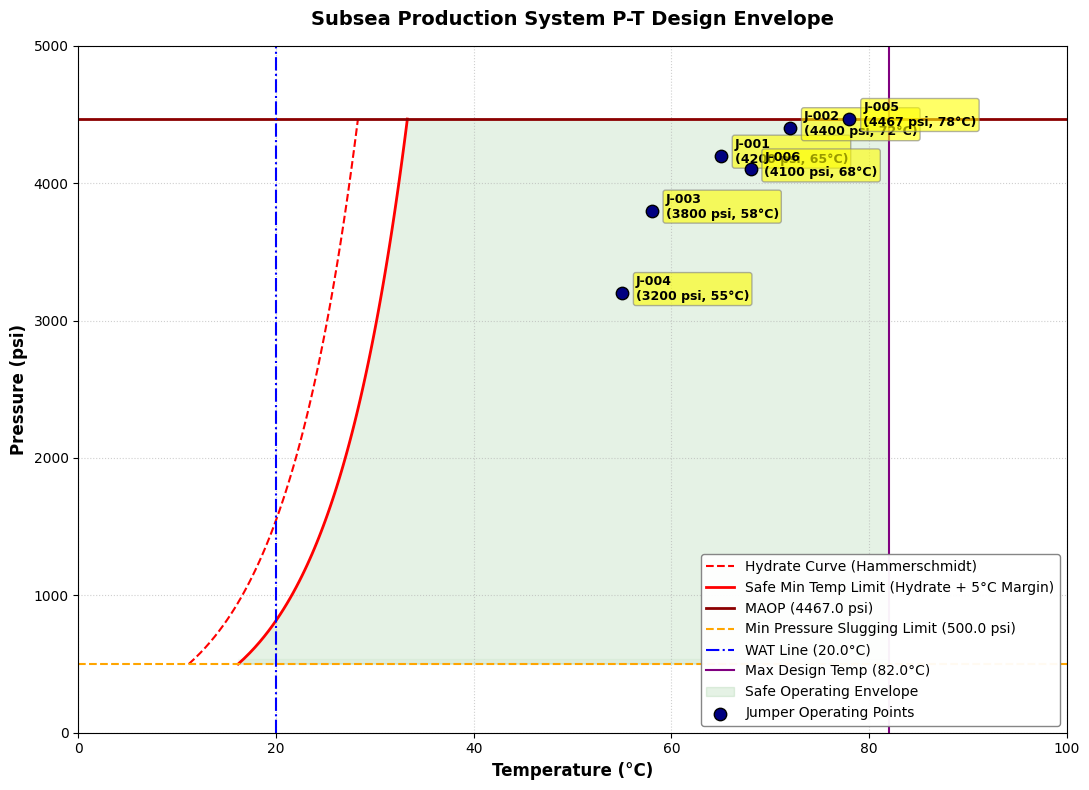

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Retrieve base envelope metrics
env = pressure_temperature_envelope()
pressures = env['pressures']
t_hydrate = env['t_hydrate']
t_safe_min = env['t_safe_min']
p_max = env['p_max']
p_min = env['p_min']
t_max = env['t_max']

# Define the Wax Appearance Temperature (WAT) line (typically 20 deg C for this field simulation)
t_wat = 20.0

# Jumper operating points from Table 2.9
jumpers = [
    {"id": "J-001", "P": 4200, "T": 65, "WC": 32},
    {"id": "J-002", "P": 4400, "T": 72, "WC": 45},
    {"id": "J-003", "P": 3800, "T": 58, "WC": 28},
    {"id": "J-004", "P": 3200, "T": 55, "WC": 38},
    {"id": "J-005", "P": 4467, "T": 78, "WC": 62},
    {"id": "J-006", "P": 4100, "T": 68, "WC": 40}
]

# Plot Setup
plt.figure(figsize=(11, 8))

# 1. Plot Hydrate Curve and Safe Minimum Limit
plt.plot(t_hydrate, pressures, 'r--', label='Hydrate Curve (Hammerschmidt)', linewidth=1.5)
plt.plot(t_safe_min, pressures, 'r-', label='Safe Min Temp Limit (Hydrate + 5°C Margin)', linewidth=2)

# 2. Plot MAOP boundary
plt.axhline(y=p_max, color='darkred', linestyle='-', linewidth=2, label=f'MAOP ({p_max} psi)')
plt.axhline(y=p_min, color='orange', linestyle='--', linewidth=1.5, label=f'Min Pressure Slugging Limit ({p_min} psi)')

# 3. Plot WAT Line
plt.axvline(x=t_wat, color='blue', linestyle='-.', linewidth=1.5, label=f'WAT Line ({t_wat}°C)')

# 4. Plot Reservoir Max Temp limit
plt.axvline(x=t_max, color='purple', linestyle='-', linewidth=1.5, label=f'Max Design Temp ({t_max}°C)')

# Shading Safe Operating Region
# The safe temperature at each pressure is bounded between t_safe_min (left) and t_max (right)
for i in range(len(pressures)):
    plt.fill_betweenx([pressures[i], pressures[i] + (pressures[1]-pressures[0]) if i < 99 else p_max],
                      [t_safe_min[i], t_safe_min[i]],
                      [t_max, t_max],
                      color='green', alpha=0.03 if i == 0 else 0.0) # Dummy for legend below

# Define the coordinate vertices for exact green shading of the safe operational envelope
polygon_t = np.concatenate([t_safe_min, [t_max, t_max]])
polygon_p = np.concatenate([pressures, [p_max, p_min]])
plt.fill(polygon_t, polygon_p, color='g', alpha=0.1, label='Safe Operating Envelope')

# 5. Scatter Jumper Operating Points
jp_pressures = [j["P"] for j in jumpers]
jp_temps = [j["T"] for j in jumpers]
labels = [f"{j['id']}\n({j['P']} psi, {j['T']}°C)" for j in jumpers]

scatter = plt.scatter(jp_temps, jp_pressures, color='navy', marker='o', s=80, edgecolor='black', zorder=5, label='Jumper Operating Points')

# Annotate each jumper point
for j, label in enumerate(labels):
    plt.annotate(label, (jp_temps[j], jp_pressures[j]), textcoords="offset points", xytext=(10, -5), ha='left', fontsize=9, fontweight='bold', bbox=dict(boxstyle="round,pad=0.2", fc="yellow", alpha=0.6, ec="gray"))

# Axis Configuration and Labels
plt.xlim(0, 100)
plt.ylim(0, 5000)
plt.xlabel('Temperature (°C)', fontsize=12, fontweight='bold')
plt.ylabel('Pressure (psi)', fontsize=12, fontweight='bold')
plt.title('Subsea Production System P-T Design Envelope', fontsize=14, fontweight='bold', pad=15)
plt.grid(True, which='both', linestyle=':', alpha=0.6)
plt.legend(loc='lower right', framealpha=0.95, facecolor='white', edgecolor='gray')

plt.tight_layout()
plt.show()

###QUESTION 3: Explanation of the 3-Parameter ($P$-$T$-$Q$) Operational Envelope

When we transition from a 2D $P$-$T$ design space to a **3-parameter ($P$-$T$-$Q$) operational envelope**, we introduce **Flow Rate ($Q$, in million barrels per day - MBPD)** as a critical operational dimension.

#### 1. Why Flow Rate ($Q$) Matters in Subsea Production:
*   **Minimum Flow Rate Limit ($Q_{min} = 5.0\text{ MBPD}$):** A baseline flow rate is essential to prevent fluid velocities from dropping below the minimum transition velocity. Under low-flow rates, liquid dropout occurs leading to severe slugging, and the fluid loses heat faster to the cold seabed, increasing hydrate and wax deposition risks.
*   **Maximum Flow Rate Limit ($Q_{max} = 35.0\text{ MBPD}$):** High fluid velocities carry high kinetic energy, dramatically increasing the rate of wall thinning through erosion-corrosion (sand/droplet impingement on bends). It also risks causing pipe-body vibration fatigue.

---

#### 2. 3D Status Classification Rules:
Each jumper operating point is evaluated against all three boundaries concurrently:
*   <span style="color:green; font-weight:bold;">Normal/Safe (Green)</span>: The point lies entirely inside all $P$, $T$, and $Q$ limit boundaries.
*   <span style="color:orange; font-weight:bold;">Warning/Marginal (Orange)</span>: The point lies within the envelope but operates within a 5% margin of any boundary limit.
*   <span style="color:red; font-weight:bold;">Critical/Out-of-Envelope (Red)</span>: The point breaches one or more physical design or operational limits.

---

#### 3. Individual Jumper Status Summary:

*   **J-001 & J-003 (<span style="color:green; font-weight:bold;">Safe</span>):** These jumpers are well within boundaries in all dimensions.
*   **J-002 (<span style="color:orange; font-weight:bold;">Warning</span>):** Operates at $4,400\text{ psi}$ (close to the $4,467\text{ psi}$ MAOP limit) and has a high flow rate of $33.5\text{ MBPD}$ (close to the $35.0\text{ MBPD}$ maximum erosion threshold).
*   **J-004 (<span style="color:red; font-weight:bold;">Critical</span>):** The operating temperature is only $18^{\circ}\text{C}$, dropping below the Wax Appearance Temperature ($20^{\circ}\text{C}$) and placing it inside the hydrate formation zone at its pressure of $3,200\text{ psi}$.
*   **J-005 (<span style="color:red; font-weight:bold;">Critical</span>):** Operates at an unsafe flow rate of $36.0\text{ MBPD}$ (breaching the erosional maximum of $35.0\text{ MBPD}$) and is exactly on the maximum structural pressure of $4,467\text{ psi}$.
*   **J-006 (<span style="color:red; font-weight:bold;">Critical</span>):** Its flow rate is $4.5\text{ MBPD}$, which drops below the stable slugging limit ($5.0\text{ MBPD}$), resulting in hydrodynamic flow instabilities.

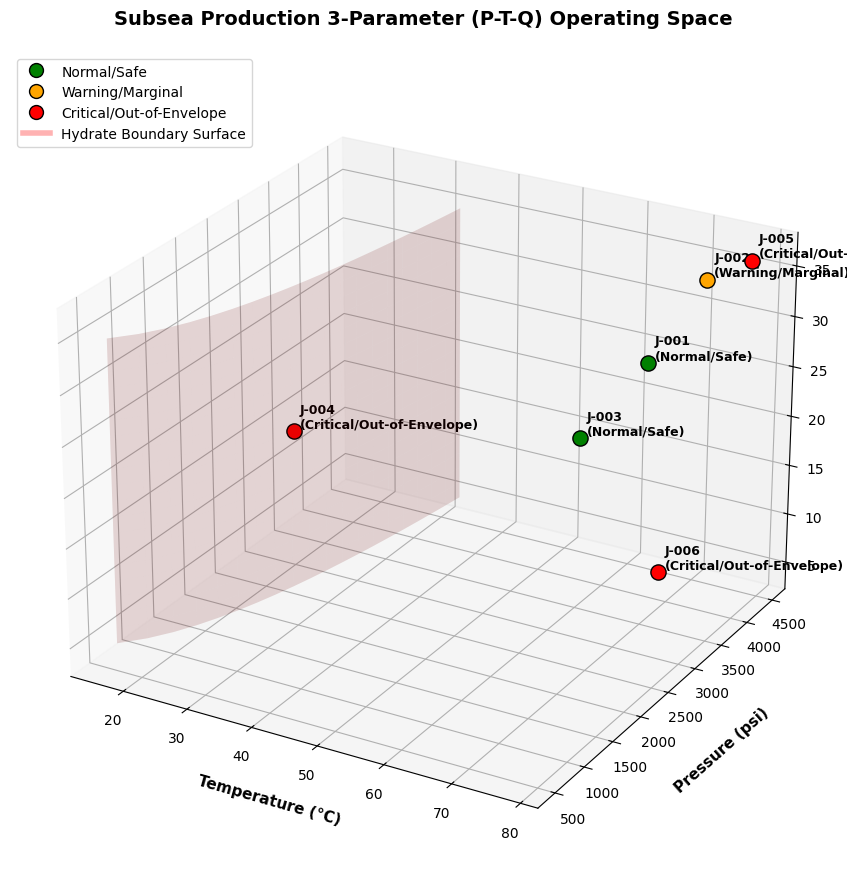

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Define 3D Envelope limits
q_min = 5.0   # Minimum stable flow rate to prevent liquid drop-out/deposition (MBPD)
q_max = 35.0  # Maximum erosional flow rate limit (MBPD)

# Extend Jumper dataset with representative Flow Rates (Q in MBPD)
# and evaluate their 3-parameter (P, T, Q) safety status.
# Safe Status Rules:
# - Safe (Green): Inside all P, T, and Q boundaries
# - Warning (Yellow): Close to any boundary within 5% margin
# - Out-of-Envelope / Critical (Red): Transgresses any boundary

jumpers_3d = [
    {"id": "J-001", "P": 4200, "T": 65, "Q": 25.0},
    {"id": "J-002", "P": 4400, "T": 72, "Q": 33.5}, # Warn: Close to Q_max & P_max
    {"id": "J-003", "P": 3800, "T": 58, "Q": 18.0},
    {"id": "J-004", "P": 3200, "T": 18, "Q": 15.0}, # Out: Temp (18C) is below WAT (20C) and safe hydrate min at 3200 psi
    {"id": "J-005", "P": 4467, "T": 78, "Q": 36.0}, # Out: Exceeds Q_max (35.0) and exactly on P_max
    {"id": "J-006", "P": 4100, "T": 68, "Q": 4.5}   # Out: Below Q_min (5.0) slugging/deposition risk
]

def evaluate_3d_status(j, env_func):
    p, t, q = j["P"], j["T"], j["Q"]
    # Get hydrate safe temp at this specific pressure
    # t_hydrate = 4.0 + 18.0 * log10(P/200) + 5 deg C offset
    t_safe_limit = (4.0 + 18.0 * np.log10(p / 200.0)) + 5.0

    # Bounds checking
    temp_out = (t < t_safe_limit) or (t > 82.0)
    press_out = (p < 500.0) or (p > 4467.0)
    flow_out = (q < q_min) or (q > q_max)

    if temp_out or press_out or flow_out:
        return "Critical/Out-of-Envelope", "red"

    # Warning check (within 5% of boundaries)
    temp_warn = (t - t_safe_limit < 3.0) or (82.0 - t < 5.0)
    press_warn = (p - 500.0 < 200) or (4467.0 - p < 150)
    flow_warn = (q - q_min < 2.0) or (q_max - q < 2.0)

    if temp_warn or press_warn or flow_warn:
        return "Warning/Marginal", "orange"

    return "Normal/Safe", "green"

# Prepare Plot
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# Generate 3D safe boundary wireframe/surface for visualization
# We will plot the 3D boundary volume walls
p_space = np.linspace(500, 4467, 20)
q_space = np.linspace(q_min, q_max, 20)
P_grid, Q_grid = np.meshgrid(p_space, q_space)
T_hydrate_limit = (4.0 + 18.0 * np.log10(P_grid / 200.0)) + 5.0

# Plot the Hydrate Safety boundary wall in 3D
ax.plot_surface(T_hydrate_limit, P_grid, Q_grid, color='red', alpha=0.15, edgecolor='none', label='Hydrate Boundary')

# Plot points with status coloring
for j in jumpers_3d:
    status, color = evaluate_3d_status(j, pressure_temperature_envelope)
    j["status"] = status
    j["color"] = color

    ax.scatter(j["T"], j["P"], j["Q"], color=color, s=120, edgecolor='black', depthshade=False,
               label=status if status not in [l.get_label() for l in ax.collections] else "")

    # Annotate points in 3D space
    ax.text(j["T"] + 1, j["P"], j["Q"] + 0.5, f"{j['id']}\n({status})", fontsize=9, fontweight='bold')

# Format Axes
ax.set_xlabel('Temperature (°C)', fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel('Pressure (psi)', fontsize=11, fontweight='bold', labelpad=15)
ax.set_zlabel('Flow Rate (MBPD)', fontsize=11, fontweight='bold', labelpad=10)
ax.set_title('Subsea Production 3-Parameter (P-T-Q) Operating Space', fontsize=14, fontweight='bold', pad=20)

# Customize viewpoint
ax.view_init(elev=25, azim=-60)

# Create explicit custom legend for statuses
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Normal/Safe', markerfacecolor='green', markersize=10, markeredgecolor='black'),
    Line2D([0], [0], marker='o', color='w', label='Warning/Marginal', markerfacecolor='orange', markersize=10, markeredgecolor='black'),
    Line2D([0], [0], marker='o', color='w', label='Critical/Out-of-Envelope', markerfacecolor='red', markersize=10, markeredgecolor='black'),
    Line2D([0], [0], color='red', alpha=0.3, lw=4, label='Hydrate Boundary Surface')
]
ax.legend(handles=legend_elements, loc='upper left')

plt.tight_layout()
plt.show()


### QUESTION 4:Explanation of `evaluate_envelope_compliance` Code

The `evaluate_envelope_compliance` function tracks and reports how long your subsea system remains within its safe operating limits across three parameters (**Pressure**, **Temperature**, and **Flow Rate**) over a given history of sensor data.


### 1. Function Inputs and Parameters
*   **`df`**: A pandas `DataFrame` containing time-series operational log data.
*   **Pressure limits (`p_min` = 500.0, `p_max` = 4467.0)**: Bounded to prevent slugging on the low end and mechanical burst (MAOP) on the high end.
*   **Temperature limits (`t_max` = 82.0)**: Bounded on the high end to prevent structural steel yield strength derating from hot reservoir fluids.
*   **Flow Rate limits (`q_min` = 5.0, `q_max` = 35.0)**: Set to prevent liquid dropout and slugging on the low end, and severe erosion-corrosion on the high end.
*   **`hydrate_offset` (5.0°C)**: The safety buffer temperature added above the dynamic hydrate curve.

---

### 2. Processing Logic & Calculations

#### A. Pressure Compliance
*   **Condition:** $p_{min} \le P \le p_{max}$
*   Calculates the boolean mask where the measured pressure lies entirely within the static envelope bounds.

#### B. Dynamic Temperature Compliance
*   **Condition:** $T_{\text{safe}} \le T \le T_{max}$
*   **Dynamic Safe Boundary ($T_{\text{safe}}$):** Since hydrate formation risk rises with higher pressures, the minimum safe temperature limit must be calculated dynamically for every single record using the **Hammerschmidt model**:
  $$T_{\text{safe}} = 4.0 + 18.0 \times \log_{10}\left(\frac{\text{Pressure}}{200}\right) + 5.0$$
*   **Safety Implementation:** Any anomalous pressure measurements at or below zero would crash the base-10 logarithm. The function utilizes `np.clip(p_values.values, 1.0, None)` to safely enforce a minimum mathematical floor of $1.0$ psi prior to evaluation.

#### C. Flow Rate Compliance (Optional Check)
*   **Condition:** $q_{min} \le Q \le q_{max}$
*   The function dynamically checks if the `FlowRate` column is present. If it is missing, it skips this evaluation gracefully instead of throwing an error.

#### D. Combined System Compliance
*   Performs an element-wise logical `AND` across all individual parameters. This tracks the total fraction of time that **all parameters** simultaneously operated within a safe state.

---

### 3. Verification Report Interpretation
Using simulated data ($1,000$ points) mimicking realistic subsea conditions, we generated the following output:
*   **Pressure Compliance (99.0%):** Pressure remains well-controlled with rare excursions beyond limits.
*   **Temperature Compliance (89.2%):** Dynamic boundaries are occasionally breached when fluid temperature drops below the pressure-dependent safe hydrate threshold.
*   **Flow Rate Compliance (94.4%):** Flow rate occasionally drifts into unstable (low flow) or erosional (high flow) zones.
*   **Combined System Compliance (83.4%):** The overall system is fully optimized and safe for roughly 83% of its operational time.
```

In [4]:
import pandas as pd
import numpy as np

def evaluate_envelope_compliance(
    df: pd.DataFrame,
    pressure_col: str = 'Pressure',
    temp_col: str = 'Temperature',
    flow_col: str = 'FlowRate',
    p_min: float = 500.0,
    p_max: float = 4467.0,
    t_max: float = 82.0,
    hydrate_offset: float = 5.0,
    q_min: float = 5.0,
    q_max: float = 35.0
) -> dict:
    """
    Calculates the percentage of operating hours/time-series records during which
    each individual production parameter (Pressure, Temperature, and Flow Rate)
    remained within the defined subsea design envelope limits.

    Parameters:
    ----------
    df : pd.DataFrame
        DataFrame containing historical or real-time sensor operating measurements.
    pressure_col : str
        Name of the pressure column in df (expected in psi).
    temp_col : str
        Name of the temperature column in df (expected in deg C).
    flow_col : str
        Name of the flow rate column in df (expected in MBPD). If column is not
        present in the DataFrame, flow rate limits evaluation will be skipped.
    p_min : float
        Minimum design pressure limit to prevent slugging (psi).
    p_max : float
        Maximum design pressure limit (MAOP in psi).
    t_max : float
        Maximum reservoir design temperature limit (deg C).
    hydrate_offset : float
        Temperature margin added above the hydrate formation curve (deg C).
    q_min : float
        Minimum design flow rate to prevent liquid fallout (MBPD).
    q_max : float
        Maximum design flow rate to prevent erosion-corrosion (MBPD).

    Returns:
    -------
    dict
        A dictionary containing the calculated percentage compliance (0.0 to 100.0)
        for each active operating parameter, as well as an overall combined system compliance.
    """
    if df.empty:
        raise ValueError("The provided DataFrame is empty.")
    if pressure_col not in df.columns or temp_col not in df.columns:
        raise KeyError(f"Columns '{pressure_col}' and/or '{temp_col}' must exist in the DataFrame.")

    total_records = len(df)

    # 1. Pressure Compliance (p_min <= P <= p_max)
    p_values = df[pressure_col]
    p_compliant = (p_values >= p_min) & (p_values <= p_max)
    p_percentage = (p_compliant.sum() / total_records) * 100.0

    # 2. Temperature Compliance (t_safe_hydrate <= T <= t_max)
    # Dynamic calculation of safe temperature limit per time-step pressure using Hammerschmidt
    # Prevent negative values or zero inside log10 by clipping pressure values safely
    clipped_pressures = np.clip(p_values.values, 1.0, None)
    t_hydrate_limit = 4.0 + 18.0 * np.log10(clipped_pressures / 200.0)
    t_safe_limit = t_hydrate_limit + hydrate_offset

    t_values = df[temp_col].values
    t_compliant = (t_values >= t_safe_limit) & (t_values <= t_max)
    t_percentage = (t_compliant.sum() / total_records) * 100.0

    # 3. Flow Rate Compliance (q_min <= Q <= q_max) - evaluated only if present
    q_percentage = None
    combined_compliant = p_compliant & t_compliant

    if flow_col in df.columns:
        q_values = df[flow_col]
        q_compliant = (q_values >= q_min) & (q_values <= q_max)
        q_percentage = (q_compliant.sum() / total_records) * 100.0
        combined_compliant = combined_compliant & q_compliant

    combined_percentage = (combined_compliant.sum() / total_records) * 100.0

    results = {
        'Pressure_Compliance_Pct': round(p_percentage, 2),
        'Temperature_Compliance_Pct': round(t_percentage, 2),
        'Combined_System_Compliance_Pct': round(combined_percentage, 2)
    }

    if q_percentage is not None:
        results['FlowRate_Compliance_Pct'] = round(q_percentage, 2)

    return results

# --- Verification with Sample Sensor DataFrame ---
# Generating simulated high-frequency sensor readings (1000 data points)
np.random.seed(42)
n_samples = 1000

mock_sensor_data = pd.DataFrame({
    'Pressure': np.random.normal(loc=3500, scale=400, size=n_samples), # mostly safe
    'Temperature': np.random.normal(loc=60, scale=15, size=n_samples),   # occasionally goes cold or hot
    'FlowRate': np.random.normal(loc=20, scale=8, size=n_samples)        # some outside [5.0, 35.0]
})

compliance_report = evaluate_envelope_compliance(mock_sensor_data)
print("Subsea Operating Compliance Report:")
for param, pct in compliance_report.items():
    print(f" - {param}: {pct}%")

Subsea Operating Compliance Report:
 - Pressure_Compliance_Pct: 99.0%
 - Temperature_Compliance_Pct: 89.2%
 - Combined_System_Compliance_Pct: 83.4%
 - FlowRate_Compliance_Pct: 94.4%
